# Who should Chenora sign first? A decision under uncertainty
**Capstone DSA 8402 · Client: Chenora (Darren Oyoo, Founder and CEO) · Option C · November 2026**

**The decision.** Which Kenyan business segments should get Chenora's sales time first, so it can reach **five paid Kenya contracts by 31 January 2027** (investor-deck Gate 2)?

**The honest starting point.** Chenora is a startup with no sales history, so there is nothing to train a model on. This notebook does not claim to *find* the best segment in data. It does three things:
1. Writes down the **commercial rules** from Darren's answers and the investor deck.
2. Tests whether the **target is realistic** with a simulation, and shows what moves the answer most.
3. Builds a transparent **prior ranking** of segments, and shows how fast real outcomes can replace it.

**Data disclosure.** All firm-level data here is **synthetic**. No real Chenora records, no real firms. Pricing and gates come from Darren and the deck. Everything else is an assumption, listed in section 2 with its source.

**How to run.** Python 3.10+ with `pandas`, `numpy` and `matplotlib`. Open the notebook and choose *Run All*. It writes data to `data/` and results to `outputs/` next to the notebook. Nothing else is needed.

**Contents.** 1 What we know · 2 Settings · 3 Pricing and gates · 4 Audit and clean · 5 Gate exploration · 6 Can we hit five? · 7 Prior ranking · 8 How fast can we learn · 9 Recommendations · 10 The tracker app

## 1. What Darren told us, and what we still do not know

In [1]:
import json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
from IPython.display import display

BASE = Path.cwd()
OUT, FIG, DATA = BASE / "outputs", BASE / "outputs" / "figures", BASE / "data"
for p in (OUT, FIG, DATA):
    p.mkdir(parents=True, exist_ok=True)

NAVY, BLUE, GREY, AMBER, GREEN = "#171B4D", "#2563EB", "#B8BED2", "#E8A317", "#12805C"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.titlecolor": NAVY, "figure.dpi": 100})

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

known = pd.DataFrame([
    ("Prospects in pipeline", "100", "Darren", "Confirmed"),
    ("Stage of those 100 prospects", "Not provided", "Darren", "UNKNOWN. We assume a split (section 2)"),
    ("Current customers", "Kijani (B2B logistics) and a second customer, read as Triply (B2B travel-tech)", "Darren", "To confirm: the answer named Kijani twice"),
    ("Triply's role", "Related party: product proof, never counted as demand", "Investor deck", "Confirmed"),
    ("Price today", "$500 a month SaaS (= $6,000 a year)", "Darren", "Confirmed"),
    ("New price", "$1 per account managed a month, plus 15% of revenue added", "Darren and deck", "Confirmed"),
    ("Minimum contract", "$12,000 a year (= 1,000 accounts x $1 x 12)", "Investor deck", "Confirmed"),
    ("How targets are chosen", "'ICP qualification criteria' (not yet written down)", "Darren", "We encode the deck's criteria as gates"),
    ("Gate 2 target", "5 Kenya customers on paid contracts by 31 January 2027", "Investor deck", "Confirmed"),
    ("Does Kijani already count as paid?", "Not stated", "None", "UNKNOWN. We assume 0"),
], columns=["Item", "What we know", "Source", "Status"])
display(known)

,Item,What we know,Source,Status
0,Prospects in pipeline,100,Darren,Confirmed
1,Stage of those 100 prospects,Not provided,Darren,UNKNOWN. We assume a split (section 2)
2,Current customers,"Kijani (B2B logistics) and a second customer, ...",Darren,To confirm: the answer named Kijani twice
3,Triply's role,"Related party: product proof, never counted as...",Investor deck,Confirmed
4,Price today,"$500 a month SaaS (= $6,000 a year)",Darren,Confirmed
5,New price,"$1 per account managed a month, plus 15% of re...",Darren and deck,Confirmed
6,Minimum contract,"$12,000 a year (= 1,000 accounts x $1 x 12)",Investor deck,Confirmed
7,How targets are chosen,'ICP qualification criteria' (not yet written ...,Darren,We encode the deck's criteria as gates
8,Gate 2 target,5 Kenya customers on paid contracts by 31 Janu...,Investor deck,Confirmed
9,Does Kijani already count as paid?,Not stated,None,UNKNOWN. We assume 0


## 2. Settings: every number, with its source
**Source tags.** `client` = Darren's answers. `deck` = Chenora investor deck V10. `desk` = public research (benchmarks). `assumption` = analyst judgement, **replace with real data as it arrives**.

The stage split of the 100 prospects is the biggest assumption, because Darren gave the total but not the stages.

In [2]:
A = dict(
    snapshot="2026-11-22", deadline="2027-01-31", target=5, pipeline=100, seed=8402,
    per_account_month=1.0, annual_minimum=12_000, revenue_share=0.15, revenue_won_back=0.02, legacy_monthly=500,
    min_accounts=1_000, tier_a_revenue=10_000_000, fx_exercise=130,
    stages=["Identified", "Contacted", "Scoping call", "Quote sent", "Negotiation"],
    sigma=0.5,
    stage_mix={"Identified": 0.55, "Contacted": 0.25, "Scoping call": 0.12, "Quote sent": 0.06, "Negotiation": 0.02},
    benchmark_win_rate=0.20,
)
# Chance a prospect at each stage ends as a paid contract, and median days to sign. ALL ASSUMPTIONS.
SCENARIOS = {
    "Pessimistic": {"win": [0.01, 0.02, 0.08, 0.20, 0.40], "days": [120, 100, 75, 45, 21]},
    "Base":        {"win": [0.02, 0.04, 0.15, 0.30, 0.55], "days": [75, 60, 45, 28, 14]},
    "Optimistic":  {"win": [0.04, 0.08, 0.25, 0.45, 0.70], "days": [50, 40, 30, 20, 10]},
}
SEGMENTS = {"b2b_software": "B2B software / SaaS", "payments": "Payments and fintech platforms",
            "logistics": "B2B logistics and freight", "travel_tech": "B2B travel-tech",
            "distributors": "Distributors and wholesalers", "manufacturers": "Manufacturers with dealer networks",
            "insurance_brokers": "Insurance brokers"}
# Prior scorecard, 0 to 5. ANALYST JUDGEMENT from Darren's answers, the deck and desk research. Meant to be overwritten.
DIMENSIONS = ["demand_evidence", "account_density", "retention_pain", "data_readiness", "reachability", "ability_to_pay"]
WEIGHTS = pd.Series([0.25, 0.20, 0.15, 0.15, 0.15, 0.10], index=DIMENSIONS)
SCORES = pd.DataFrame({
    "b2b_software":      [3, 4, 5, 5, 4, 2], "payments":          [2, 5, 4, 5, 2, 4],
    "logistics":         [4, 3, 4, 3, 4, 3], "travel_tech":       [2, 3, 3, 4, 3, 3],
    "distributors":      [1, 4, 4, 2, 3, 3], "manufacturers":     [1, 3, 3, 2, 3, 4],
    "insurance_brokers": [1, 2, 4, 3, 3, 3]}, index=DIMENSIONS).T.astype(float)
# Synthetic-universe parameters (generation only, NOT market estimates).
U = dict(n=600,
         mix={"b2b_software": .20, "payments": .12, "logistics": .16, "travel_tech": .10, "distributors": .18, "manufacturers": .14, "insurance_brokers": .10},
         median_accounts={"b2b_software": 600, "payments": 2000, "logistics": 450, "travel_tech": 700, "distributors": 900, "manufacturers": 400, "insurance_brokers": 1200},
         p_digital={"b2b_software": .95, "payments": .90, "logistics": .65, "travel_tech": .80, "distributors": .35, "manufacturers": .45, "insurance_brokers": .60},
         p_access=0.60,
         rev_per_account={"b2b_software": 1200, "payments": 400, "logistics": 1500, "travel_tech": 900, "distributors": 600, "manufacturers": 2500, "insurance_brokers": 350},
         sources=["Founder network", "Referral", "Outbound email", "Partner introduction", "Event", "Registry list"])

register = pd.DataFrame([
    ("Pipeline size", "100", "client"), ("Stage split of the 100", " / ".join(f"{v:.0%}" for v in A["stage_mix"].values()) + " across the five active stages", "ASSUMPTION (to confirm)"),
    ("Target and date", "5 paid Kenya contracts by 31 Jan 2027", "deck"), ("Price per account per month", "$1", "client + deck"),
    ("Minimum annual fee", "$12,000", "deck"), ("Revenue share", "15% of revenue won back", "client + deck"),
    ("Revenue won back, per firm", "2% of annual revenue (deck range 2% to 3%)", "deck, applied as an assumption"),
    ("ICP gates", "1,000+ accounts, digital records, decision-maker access", "deck"),
    ("Win rates and signing times", "Three scenarios, see SCENARIOS", "ASSUMPTION"),
    ("B2B average win rate (context)", "about 19 to 20% for qualified opportunities", "desk (Ebsta x Pavilion, via Gradient Works)"),
    ("Segment prior scores", "0 to 5 on six dimensions", "ASSUMPTION (analyst judgement)"),
    ("KES per USD", "130, used only for the planted unit problem", "exercise, not a market rate"),
], columns=["Setting", "Value", "Source"])
display(register)

,Setting,Value,Source
0,Pipeline size,100,client
1,Stage split of the 100,55% / 25% / 12% / 6% / 2% across the five acti...,ASSUMPTION (to confirm)
2,Target and date,5 paid Kenya contracts by 31 Jan 2027,deck
3,Price per account per month,$1,client + deck
4,Minimum annual fee,"$12,000",deck
5,Revenue share,15% of revenue won back,client + deck
6,"Revenue won back, per firm",2% of annual revenue (deck range 2% to 3%),"deck, applied as an assumption"
7,ICP gates,"1,000+ accounts, digital records, decision-mak...",deck
8,Win rates and signing times,"Three scenarios, see SCENARIOS",ASSUMPTION
9,B2B average win rate (context),about 19 to 20% for qualified opportunities,"desk (Ebsta x Pavilion, via Gradient Works)"


## 3. The commercial rules, in numbers
The minimum fee and the account gate are the same rule seen twice: 1,000 accounts at $1 a month is exactly $12,000 a year.
So **"1,000+ accounts" is the price floor, not a preference.** That makes it a hard gate, not a score.

,accounts,revenue per account (USD),platform fee,revenue share,year-one value
0,500,600,12000.0,900,12900
1,500,1500,12000.0,2250,14250
2,1000,600,12000.0,1800,13800
3,1000,1500,12000.0,4500,16500
4,2000,600,24000.0,3600,27600
5,2000,1500,24000.0,9000,33000
6,3000,600,36000.0,5400,41400
7,3000,1500,36000.0,13500,49500
8,5000,600,60000.0,9000,69000
9,5000,1500,60000.0,22500,82500


Legacy price: USD 6,000 a year. Under the new pricing the floor is USD 12,000.
Five Kenya contracts at the gate size are worth about USD 60,000 a year in platform fees.


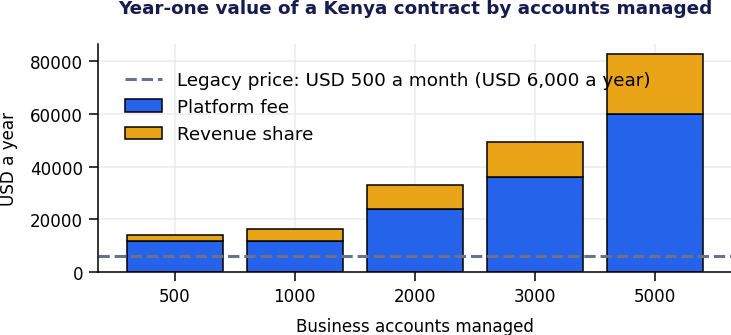

In [3]:
def platform_fee(accounts):
    return np.maximum(np.asarray(accounts, dtype=float) * A["per_account_month"] * 12, A["annual_minimum"])

def revenue_share_fee(revenue):
    return np.asarray(revenue, dtype=float) * A["revenue_won_back"] * A["revenue_share"]

rows = []
for acc in (500, 1000, 2000, 3000, 5000):
    for rev_pa in (600, 1500):
        plat, share = float(platform_fee(acc)), float(revenue_share_fee(acc * rev_pa))
        rows.append({"accounts": acc, "revenue per account (USD)": rev_pa, "platform fee": plat,
                     "revenue share": round(share), "year-one value": round(plat + share)})
price_table = pd.DataFrame(rows)
display(price_table)

legacy = A["legacy_monthly"] * 12
five_at_gate = 5 * A["annual_minimum"]
print(f"Legacy price: USD {legacy:,} a year. Under the new pricing the floor is USD {A['annual_minimum']:,}.")
print(f"Five Kenya contracts at the gate size are worth about USD {five_at_gate:,} a year in platform fees.")

sub = price_table[price_table["revenue per account (USD)"] == 1500].set_index("accounts")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(sub.index.astype(str), sub["platform fee"], color=BLUE, label="Platform fee")
ax.bar(sub.index.astype(str), sub["revenue share"], bottom=sub["platform fee"], color=AMBER, label="Revenue share")
ax.axhline(legacy, color="#6B7189", ls="--", label="Legacy price: USD 500 a month (USD 6,000 a year)")
ax.set_title("Year-one value of a Kenya contract by accounts managed"); ax.set_xlabel("Business accounts managed")
ax.set_ylabel("USD a year"); ax.legend(frameon=False, loc="upper left")
save("01_contract_value")

**Reading this.** A Kenyan firm just above the gate is worth roughly $12,000 to $17,000 in year one, far below the deck's $84K planning average. Gate 2 therefore proves *repeatability in Kenya*, not revenue scale. Darren should also confirm whether the $12,000 minimum applies in Kenya, because today's $500 a month ($6,000 a year) sits below it.

## 4. The synthetic prospect universe: audit and clean
600 fictional firms across seven segments, with **deliberate, documented data problems** planted so the cleaning is real work. The log below lists exactly what was planted.

Planted problems: {'missing_revenue': 30, 'missing_digital_records_flag': 20, 'segment_label_variants': 25, 'accounts_as_text_k': 10, 'negative_account_counts': 4, 'revenue_in_kes': 15, 'duplicate_rows': 12}


,issue,count
0,rows,612
1,duplicate firm_id rows,12
2,missing annual_revenue_usd,31
3,missing has_digital_records,20
4,accounts stored as text (e.g. '1.2k'),10
5,negative accounts_managed,4
6,revenue reported in KES,16
7,segment labels that are not standard ids,26


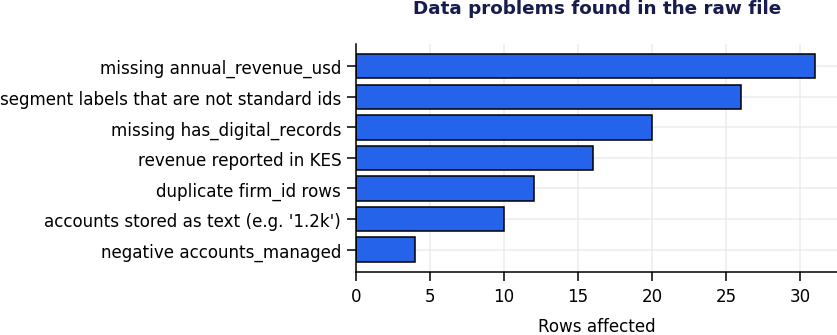

In [4]:
COUNTIES = ["Nairobi", "Kiambu", "Mombasa", "Nakuru", "Kisumu", "Uasin Gishu", "Machakos", "Other"]
COUNTY_P = [0.50, 0.10, 0.10, 0.08, 0.06, 0.05, 0.05, 0.06]
PREFIX = {"b2b_software": "SW", "payments": "PY", "logistics": "LG", "travel_tech": "TT", "distributors": "DS", "manufacturers": "MF", "insurance_brokers": "IB"}

def generate_universe(seed=A["seed"]):
    rng = np.random.default_rng(seed)
    segs = list(U["mix"]); p = np.array([U["mix"][s] for s in segs]); p = p / p.sum()
    rows, counter = [], {s: 0 for s in segs}
    for s in rng.choice(segs, size=U["n"], p=p):
        counter[s] += 1
        acc = float(np.clip(rng.lognormal(np.log(U["median_accounts"][s]), 0.9), 50, 60000))
        rev_pa = U["rev_per_account"][s] * rng.lognormal(0, 0.5)
        rows.append({
            "firm_id": f"{PREFIX[s]}-{counter[s]:03d}", "firm_name": f"Fictional {SEGMENTS[s].split(' / ')[0].split(' and ')[0]} firm {PREFIX[s]}-{counter[s]:03d}",
            "segment": s, "county": rng.choice(COUNTIES, p=COUNTY_P),
            "accounts_managed": round(acc), "annual_revenue_usd": round(acc * rev_pa, -3),
            "has_digital_records": "Yes" if rng.random() < U["p_digital"][s] else "No",
            "decision_maker_access": "Yes" if rng.random() < U["p_access"] else "No",
            "lead_source": rng.choice(U["sources"])})
    return pd.DataFrame(rows)

def inject_issues(clean_df, seed=A["seed"] + 1):
    rng = np.random.default_rng(seed)
    raw, n, log = clean_df.copy(), len(clean_df), {}
    raw["revenue_currency"] = "USD"
    idx = rng.choice(n, 30, replace=False); raw.loc[idx, "annual_revenue_usd"] = np.nan; log["missing_revenue"] = 30
    idx = rng.choice(n, 20, replace=False); raw.loc[idx, "has_digital_records"] = np.nan; log["missing_digital_records_flag"] = 20
    idx = rng.choice(n, 25, replace=False)
    raw.loc[idx, "segment"] = raw.loc[idx, "segment"].map(lambda s: "  " + s.replace("_", " ").upper() + " "); log["segment_label_variants"] = 25
    idx = rng.choice(n, 10, replace=False)
    raw["accounts_managed"] = raw["accounts_managed"].astype(object)
    raw.loc[idx, "accounts_managed"] = raw.loc[idx, "accounts_managed"].map(lambda v: f"{v/1000:.1f}k"); log["accounts_as_text_k"] = 10
    idx = rng.choice(n, 4, replace=False)
    raw.loc[idx, "accounts_managed"] = -1 * pd.to_numeric(raw.loc[idx, "accounts_managed"].astype(str).str.replace("k", "e3"), errors="coerce")
    log["negative_account_counts"] = 4
    idx = rng.choice(n, 15, replace=False)
    raw.loc[idx, "revenue_currency"] = "KES"; raw.loc[idx, "annual_revenue_usd"] = raw.loc[idx, "annual_revenue_usd"] * A["fx_exercise"]
    log["revenue_in_kes"] = 15
    raw = pd.concat([raw, raw.sample(12, random_state=11)], ignore_index=True); log["duplicate_rows"] = 12
    return raw, log

def generate_pipeline(seed=A["seed"] + 2, n=A["pipeline"]):
    # 100 fictional prospects in the shape of the tracker app. The stage mix is the ASSUMED one, not Darren's real mix.
    from datetime import timedelta
    rng = np.random.default_rng(seed)
    segs = list(U["mix"]); p = np.array([U["mix"][s] for s in segs]); p = p / p.sum()
    seg = rng.choice(segs, size=n, p=p)
    mix = A["stage_mix"]
    stages = rng.choice(list(mix), size=n, p=np.array(list(mix.values())) / sum(mix.values()))
    snap = pd.Timestamp(A["snapshot"]).to_pydatetime()
    rows = []
    for i, (s, st) in enumerate(zip(seg, stages), start=1):
        acc = float(np.clip(rng.lognormal(np.log(2.0 * A["min_accounts"]), 0.6), 150, 60000))
        rev = acc * U["rev_per_account"][s] * rng.lognormal(0, 0.5)
        added = int(rng.integers(5, 120)); last = int(rng.integers(0, min(added, 30) + 1))
        rows.append({"prospect_code": f"KE-{i:03d}", "segment": s, "accounts_managed": round(acc), "annual_revenue_usd": round(rev, -3),
                     "has_digital_records": "Yes" if rng.random() < 0.95 else "No", "decision_maker_access": "Yes" if rng.random() < 0.95 else "No",
                     "lead_source": rng.choice(U["sources"]), "stage": st,
                     "date_added": (snap - timedelta(days=added)).date(), "last_stage_change": (snap - timedelta(days=last)).date(),
                     "owner": "Founder", "why_won_or_lost": ""})
    return pd.DataFrame(rows)

universe = generate_universe()
raw, planted = inject_issues(universe)
raw.to_csv(DATA / "prospect_universe_raw.csv", index=False)
generate_pipeline().to_csv(DATA / "sample_pipeline.csv", index=False)   # the file the tracker app loads as sample data
print("Planted problems:", planted)

def audit(df):
    acc = pd.to_numeric(df["accounts_managed"], errors="coerce")
    items = {"rows": len(df), "duplicate firm_id rows": int(df["firm_id"].duplicated().sum()),
             "missing annual_revenue_usd": int(df["annual_revenue_usd"].isna().sum()),
             "missing has_digital_records": int(df["has_digital_records"].isna().sum()),
             "accounts stored as text (e.g. '1.2k')": int(df["accounts_managed"].astype(str).str.contains("k", case=False).sum()),
             "negative accounts_managed": int((acc < 0).sum()), "revenue reported in KES": int((df["revenue_currency"] == "KES").sum()),
             "segment labels that are not standard ids": int((~df["segment"].astype(str).str.fullmatch(r"[a-z0-9_]+")).sum())}
    return pd.DataFrame({"issue": list(items), "count": list(items.values())})

audit_table = audit(raw)
display(audit_table)
a = audit_table[audit_table["issue"] != "rows"].set_index("issue")["count"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.barh(a.index, a.values, color=BLUE)
ax.set_title("Data problems found in the raw file"); ax.set_xlabel("Rows affected")
save("02_audit")

### Cleaning decisions
- **Duplicates:** removed by `firm_id` after the audit.
- **Segment labels:** trimmed and mapped to standard ids. Any unknown label stops the run.
- **Accounts stored as text ("1.2k"):** parsed to numbers. **Negative counts** are impossible, so they become missing, never sign-flipped.
- **Revenue in KES:** converted at the exercise rate of 130 per USD. That rate exists only for this exercise.
- **Missing values stay missing.** We do not invent revenue, account counts or flags. A firm with unknown accounts cannot be gated.

In [5]:
def gates(df):
    acc = pd.to_numeric(df["accounts_managed"], errors="coerce")
    rev = pd.to_numeric(df["annual_revenue_usd"], errors="coerce")
    yes = lambda s: s.astype(str).str.lower().eq("yes")
    out = df.copy()
    ok_acc, ok_dig, ok_dm = acc >= A["min_accounts"], yes(df["has_digital_records"]), yes(df["decision_maker_access"])
    out["icp_pass"] = ok_acc & ok_dig & ok_dm
    reasons = []
    for i in range(len(out)):
        r = []
        if not ok_acc.iloc[i]: r.append("fewer than 1,000 accounts" if pd.notna(acc.iloc[i]) else "accounts unknown")
        if not ok_dig.iloc[i]: r.append("no digital records")
        if not ok_dm.iloc[i]: r.append("no decision-maker access")
        reasons.append("; ".join(r))
    out["icp_fail_reason"] = reasons
    out["icp_tier"] = np.where(~out["icp_pass"], "Not eligible", np.where(rev >= A["tier_a_revenue"], "A", "B"))
    return out

def clean(raw_df):
    log, df = {}, raw_df.copy()
    before = len(df); df = df.drop_duplicates("firm_id").copy(); log["duplicates_removed"] = before - len(df)
    df["segment"] = df["segment"].astype(str).str.strip().str.lower().str.replace(" ", "_", regex=False)
    unknown = set(df["segment"]) - set(SEGMENTS); assert not unknown, f"Unmapped segment labels: {unknown}"
    def parse(v):
        if isinstance(v, str):
            import re
            m = re.fullmatch(r"\s*([\d.]+)\s*k\s*", v.lower())
            return float(m.group(1)) * 1000 if m else pd.to_numeric(v, errors="coerce")
        return v
    df["accounts_managed"] = df["accounts_managed"].map(parse).astype(float)
    log["negative_accounts_set_to_missing"] = int((df["accounts_managed"] < 0).sum())
    df.loc[df["accounts_managed"] < 0, "accounts_managed"] = np.nan
    kes = df["revenue_currency"] == "KES"
    df.loc[kes, "annual_revenue_usd"] = df.loc[kes, "annual_revenue_usd"] / A["fx_exercise"]
    log["revenue_converted_from_kes"] = int(kes.sum()); df["revenue_currency"] = "USD"
    df = gates(df)
    df["annual_platform_fee_usd"] = platform_fee(df["accounts_managed"].fillna(0))
    df["est_year_one_value_usd"] = df["annual_platform_fee_usd"] + np.nan_to_num(revenue_share_fee(df["annual_revenue_usd"]), nan=0.0)
    df.loc[df["accounts_managed"].isna(), ["annual_platform_fee_usd", "est_year_one_value_usd"]] = np.nan
    assert df["firm_id"].is_unique
    return df.reset_index(drop=True), log

df, clog = clean(raw)
df.to_csv(DATA / "prospect_universe_clean.csv", index=False)
print(clog)
print("Rows:", len(raw), "->", len(df), "| unique firms:", df.firm_id.nunique())
display(df.head(5))

{'duplicates_removed': 12, 'negative_accounts_set_to_missing': 4, 'revenue_converted_from_kes': 15}
Rows: 612 -> 600 | unique firms: 600


,firm_id,firm_name,segment,county,accounts_managed,annual_revenue_usd,has_digital_records,decision_maker_access,lead_source,revenue_currency,icp_pass,icp_fail_reason,icp_tier,annual_platform_fee_usd,est_year_one_value_usd
0,DS-001,Fictional Distributors firm DS-001,distributors,Nakuru,153.0,80000.0,No,Yes,Registry list,USD,False,"fewer than 1,000 accounts; no digital records",Not eligible,12000.0,12240.0
1,MF-001,Fictional Manufacturers with dealer networks f...,manufacturers,Nakuru,57.0,132000.0,No,Yes,Founder network,USD,False,"fewer than 1,000 accounts; no digital records",Not eligible,12000.0,12396.0
2,MF-002,Fictional Manufacturers with dealer networks f...,manufacturers,Nairobi,2181.0,16965000.0,Yes,Yes,Outbound email,USD,True,,A,26172.0,77067.0
3,LG-001,Fictional B2B logistics firm LG-001,logistics,Nairobi,522.0,721000.0,Yes,No,Event,USD,False,"fewer than 1,000 accounts; no decision-maker a...",Not eligible,12000.0,14163.0
4,PY-001,Fictional Payments firm PY-001,payments,Kisumu,5329.0,3138000.0,Yes,Yes,Referral,USD,True,,B,63948.0,73362.0


## 5. Exploring the universe against the ICP gates
Gates: **1,000+ business accounts**, **digital records** to connect (CRM or billing), **access to the decision maker**. Tier A also has $10M+ revenue (the deck's first segment). Tier B is "Kenya mid-market for speed".

*Caution.* The share passing is driven by the synthetic parameters, so read these charts as a demonstration of the gating logic, not as market sizes.

,firms,pass_rate,median_accounts,median_year_one_value
B2B software / SaaS,113,0.13,564.0,13968.0
Payments and fintech platforms,79,0.42,1802.0,25029.0
B2B logistics and freight,104,0.09,514.5,14563.5
B2B travel-tech,51,0.04,705.0,13785.0
Distributors and wholesalers,113,0.18,890.0,13938.0
Manufacturers with dealer networks,89,0.04,363.0,14511.0
Insurance brokers,51,0.22,1113.0,14718.0


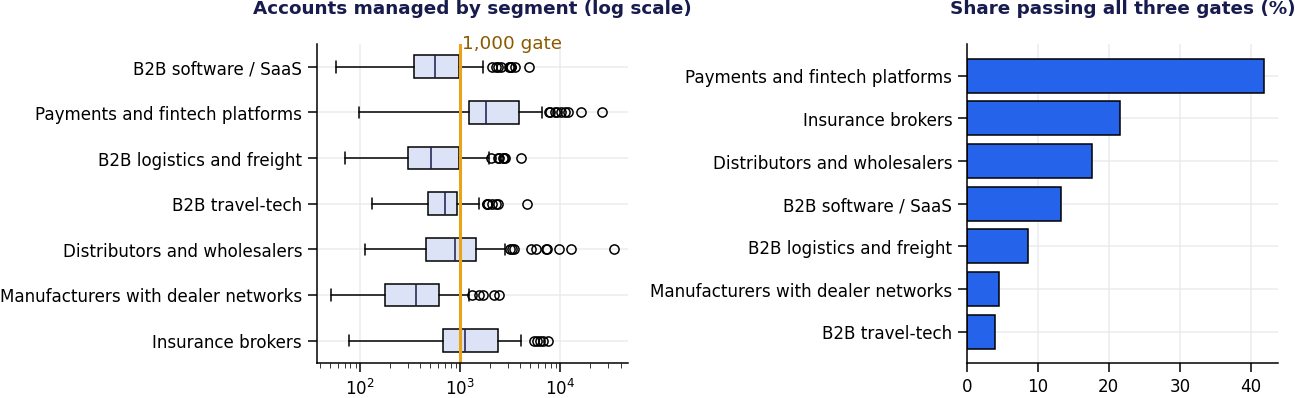

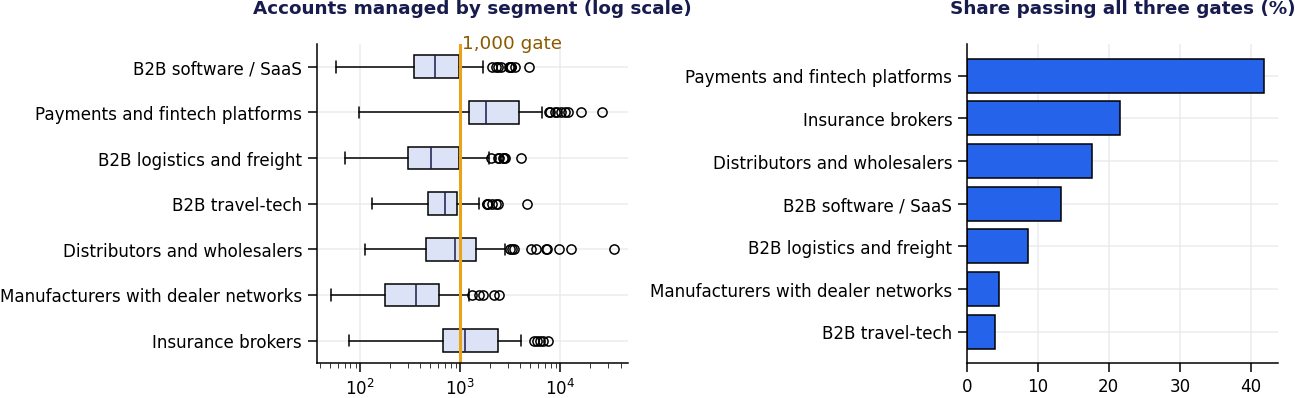

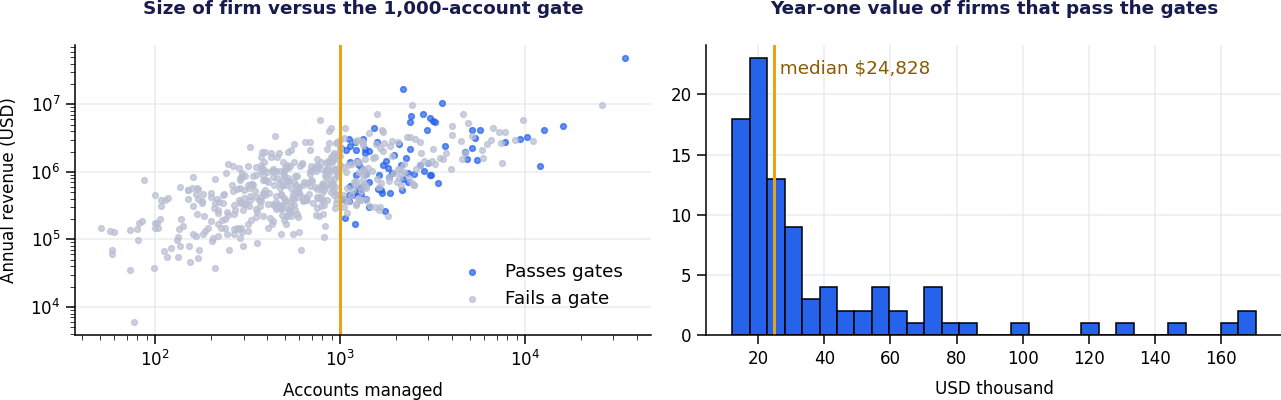

Firms passing all gates: 94 of 600 | tier A: 3 | tier B: 91 | median year-one value of passing firms: $ 24828


,firms
icp_fail_reason,
"fewer than 1,000 accounts",142
"fewer than 1,000 accounts; no decision-maker access",94
"fewer than 1,000 accounts; no digital records",87
no decision-maker access,62
"fewer than 1,000 accounts; no digital records; no decision-maker access",54
no digital records,44


In [6]:
seg_order = list(SEGMENTS)
g = df.groupby("segment").agg(firms=("firm_id", "size"), pass_rate=("icp_pass", "mean"), median_accounts=("accounts_managed", "median"),
                              median_year_one_value=("est_year_one_value_usd", "median")).reindex(seg_order)
g.index = [SEGMENTS[i] for i in g.index]
display(g.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data = [df.loc[df.segment == s, "accounts_managed"].dropna() for s in seg_order]
try:                                   # newer matplotlib uses orientation=, older uses vert=
    axes[0].boxplot(data, orientation="horizontal", patch_artist=True, boxprops=dict(facecolor="#DCE3F7"), medianprops=dict(color=NAVY))
except TypeError:
    axes[0].boxplot(data, vert=False, patch_artist=True, boxprops=dict(facecolor="#DCE3F7"), medianprops=dict(color=NAVY))
axes[0].set_yticks(range(1, len(seg_order) + 1)); axes[0].set_yticklabels([SEGMENTS[s] for s in seg_order])
axes[0].set_xscale("log"); axes[0].axvline(1000, color=AMBER, lw=2); axes[0].text(1050, 0.6, "1,000 gate", color="#8A5A00")
axes[0].set_title("Accounts managed by segment (log scale)"); axes[0].invert_yaxis()
pr = g["pass_rate"].sort_values()
axes[1].barh(pr.index, pr.values * 100, color=BLUE); axes[1].set_title("Share passing all three gates (%)")
save("03_gates_by_segment")

ok = df.dropna(subset=["accounts_managed", "annual_revenue_usd"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for flag, col, lab in [(True, BLUE, "Passes gates"), (False, GREY, "Fails a gate")]:
    s = ok[ok.icp_pass == flag]
    axes[0].scatter(s.accounts_managed, s.annual_revenue_usd, s=14, color=col, alpha=0.7, label=lab)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].axvline(1000, color=AMBER)
axes[0].set_xlabel("Accounts managed"); axes[0].set_ylabel("Annual revenue (USD)"); axes[0].legend(frameon=False, loc="lower right")
axes[0].set_title("Size of firm versus the 1,000-account gate")
v = df.loc[df.icp_pass, "est_year_one_value_usd"].dropna(); vk = v / 1000
axes[1].hist(vk.clip(upper=vk.quantile(0.98)), bins=30, color=BLUE)
axes[1].axvline(vk.median(), color=AMBER, lw=2); axes[1].text(vk.median(), axes[1].get_ylim()[1] * 0.9, f" median ${v.median():,.0f}", color="#8A5A00")
axes[1].set_title("Year-one value of firms that pass the gates"); axes[1].set_xlabel("USD thousand")
save("04_size_and_value")
n_pass, tier_a, tier_b = int(df.icp_pass.sum()), int((df.icp_tier == "A").sum()), int((df.icp_tier == "B").sum())
print("Firms passing all gates:", n_pass, "of", len(df), "| tier A:", tier_a, "| tier B:", tier_b, "| median year-one value of passing firms: $", round(v.median()))
display(df.loc[~df.icp_pass, "icp_fail_reason"].value_counts().head(6).to_frame("firms"))

## 6. Can Chenora reach five paid contracts by 31 January?
**Model.** Each active prospect ends as a paid contract with a stage-specific chance, and signs after a log-normal delay. The chance of signing *before the deadline* is `win chance x P(delay <= days left)`. We simulate 20,000 pipelines per scenario.

**What is assumed.** Darren gave the total (100) but not the stage split, so we assume a conservative one. Win chances and signing times are scenario assumptions. Early stages sit well below the 19 to 20% B2B average win rate, which applies to qualified opportunities.

Days from the snapshot to the deadline: 70. Assumed split of the 100 prospects: {'Identified': 55, 'Contacted': 25, 'Scoping call': 12, 'Quote sent': 6, 'Negotiation': 2}


,Scenario,P(5+ contracts),Expected,10th to 90th percentile,Extra prospects at Quote sent for 80% chance,Extra prospects at Scoping call for 80% chance
0,Pessimistic,0.07,2.4,1 to 4,25,119
1,Base,0.66,5.4,3 to 8,4,9
2,Optimistic,0.99,10.3,7 to 14,0,0


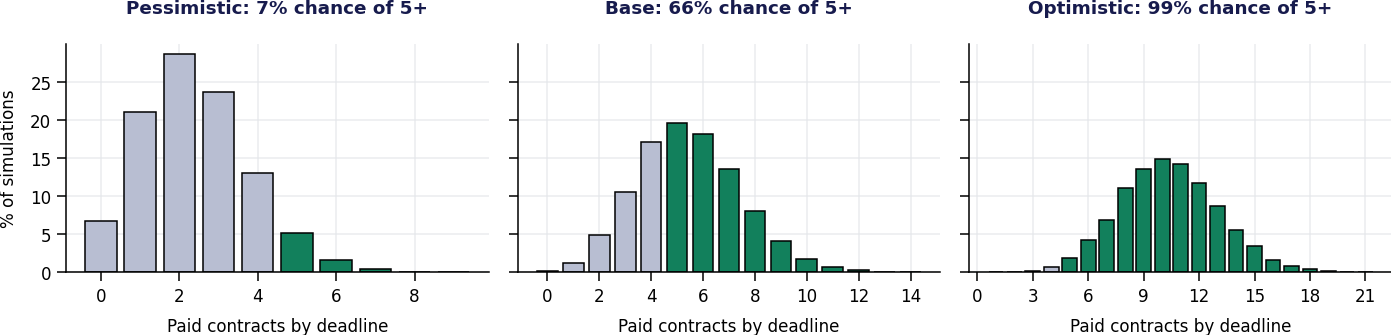

In [7]:
def norm_cdf(x): return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def stage_probs(scn, days, mult=1.0):
    if days <= 0: return [0.0] * 5
    return [min(1.0, w * mult) * norm_cdf((math.log(days) - math.log(d)) / A["sigma"]) for w, d in zip(scn["win"], scn["days"])]

def simulate(counts, scn, days, target=A["target"], already_won=0, mult=1.0, n=20000, seed=42):
    rng = np.random.default_rng(seed)
    wins = np.zeros(n, dtype=int)
    for c, p in zip(counts, stage_probs(scn, days, mult)):
        if c > 0: wins += rng.binomial(int(c), p, n)
    wins = wins + already_won
    return {"p": float((wins >= target).mean()), "mean": float(wins.mean()), "p10": float(np.percentile(wins, 10)),
            "p90": float(np.percentile(wins, 90)), "draws": wins}

def extra_needed(counts, scn, days, stage_idx, confidence=0.8, cap=5000):
    # Extra prospects at one stage that lift P(target) to the confidence level. None if out of reach.
    def ok(extra):
        c = list(counts); c[stage_idx] += extra
        return simulate(c, scn, days, n=4000)["p"] >= confidence
    if ok(0): return 0
    hi = 1
    while not ok(hi):
        hi *= 2
        if hi > cap: return None
    lo = hi // 2
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if ok(mid): hi = mid
        else: lo = mid
    return hi

days = (pd.Timestamp(A["deadline"]) - pd.Timestamp(A["snapshot"])).days
counts = [round(A["pipeline"] * A["stage_mix"][s]) for s in A["stages"]]
print(f"Days from the snapshot to the deadline: {days}. Assumed split of the 100 prospects: {dict(zip(A['stages'], counts))}")

res, tbl = {}, []
for name, scn in SCENARIOS.items():
    r = simulate(counts, scn, days); res[name] = r
    tbl.append({"Scenario": name, "P(5+ contracts)": round(r["p"], 2), "Expected": round(r["mean"], 1), "10th to 90th percentile": f"{r['p10']:.0f} to {r['p90']:.0f}",
                "Extra prospects at Quote sent for 80% chance": extra_needed(counts, scn, days, 3),
                "Extra prospects at Scoping call for 80% chance": extra_needed(counts, scn, days, 2)})
feas = pd.DataFrame(tbl); display(feas)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (name, r) in zip(axes, res.items()):
    d = pd.Series(r["draws"]).value_counts(normalize=True).sort_index() * 100
    ax.bar(d.index, d.values, color=[GREEN if i >= A["target"] else GREY for i in d.index])
    ax.set_title(f"{name}: {r['p']:.0%} chance of 5+"); ax.set_xlabel("Paid contracts by deadline")
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
axes[0].set_ylabel("% of simulations")
save("05_feasibility_by_scenario")

### What moves the answer most
Whether five is realistic hinges mostly on **how many of the 100 prospects are already at Quote sent or Negotiation**, and on how much time is left. That is the first thing to ask Darren.

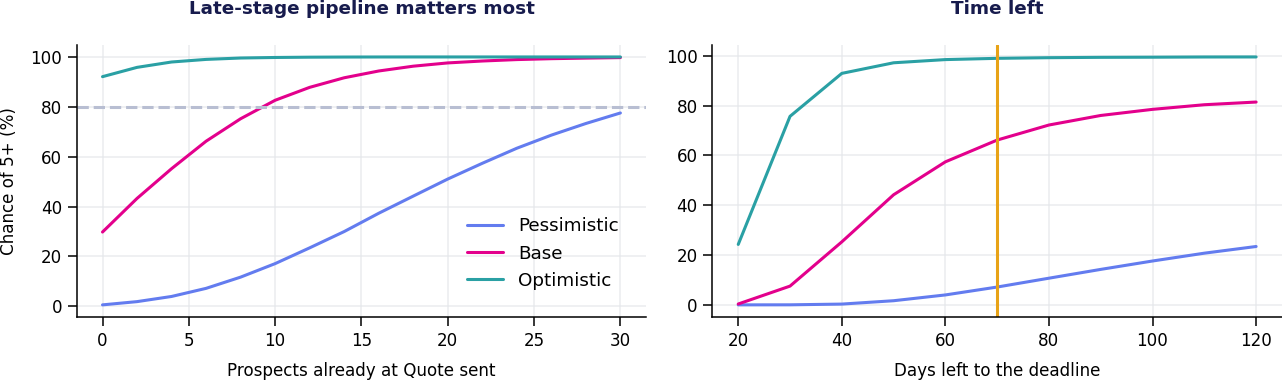

,Change (Base scenario),P(target),Shift (points)
0,Win rates 30% lower,0.32,-34
1,Win rates 30% higher,0.88,22
4,+5 prospects at Quote sent,0.86,20
5,+10 prospects at Scoping call,0.83,17
2,15 fewer days,0.52,-15
3,15 more days,0.74,8


In [8]:
base = SCENARIOS["Base"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, scn in SCENARIOS.items():
    xs = list(range(0, 31, 2)); ys = []
    for q in xs:
        c = list(counts); c[3] = q; c[0] = A["pipeline"] - sum(c[1:])
        ys.append(simulate(c, scn, days)["p"] * 100)
    axes[0].plot(xs, ys, lw=2, label=name)
axes[0].axhline(80, color=GREY, ls="--"); axes[0].set_xlabel("Prospects already at Quote sent"); axes[0].set_ylabel("Chance of 5+ (%)")
axes[0].set_title("Late-stage pipeline matters most"); axes[0].legend(frameon=False, loc="lower right")
for name, scn in SCENARIOS.items():
    ds = list(range(20, 121, 10))
    axes[1].plot(ds, [simulate(counts, scn, d)["p"] * 100 for d in ds], lw=2, label=name)
axes[1].axvline(days, color=AMBER); axes[1].set_xlabel("Days left to the deadline"); axes[1].set_title("Time left")
save("06_what_moves_the_answer")

b = res["Base"]["p"]
def pb(c=counts, d=days, m=1.0): return simulate(c, base, d, mult=m)["p"]
def bump(i, k): c = list(counts); c[i] += k; return c
stress = pd.DataFrame([{"Change (Base scenario)": lab, "P(target)": round(val, 2), "Shift (points)": round((val - b) * 100)} for lab, val in [
    ("Win rates 30% lower", pb(m=0.7)), ("Win rates 30% higher", pb(m=1.3)), ("15 fewer days", pb(d=days - 15)),
    ("15 more days", pb(d=days + 15)), ("+5 prospects at Quote sent", pb(c=bump(3, 5))), ("+10 prospects at Scoping call", pb(c=bump(2, 10)))]])
stress = stress.sort_values("Shift (points)", key=abs, ascending=False); display(stress)

## 7. A transparent prior ranking of segments
With no outcome data, a ranking can only be a **structured opinion**. Each segment is scored 0 to 5 on six dimensions. The scores come from Darren's answers (Kijani is the one real customer), the deck and desk research. **They are analyst judgement, written down so they can be challenged and overwritten.** The scorecard does not use the synthetic outcomes, so it cannot be circular.

,demand_evidence,account_density,retention_pain,data_readiness,reachability,ability_to_pay
B2B software / SaaS,3.0,4.0,5.0,5.0,4.0,2.0
Payments and fintech platforms,2.0,5.0,4.0,5.0,2.0,4.0
B2B logistics and freight,4.0,3.0,4.0,3.0,4.0,3.0
B2B travel-tech,2.0,3.0,3.0,4.0,3.0,3.0
Distributors and wholesalers,1.0,4.0,4.0,2.0,3.0,3.0
Manufacturers with dealer networks,1.0,3.0,3.0,2.0,3.0,4.0
Insurance brokers,1.0,2.0,4.0,3.0,3.0,3.0


,fit score (0-100),top1_share,top3_share,median_rank
B2B software / SaaS,77.0,0.78,1.0,1.0
B2B logistics and freight,71.0,0.10,1.0,3.0
Payments and fintech platforms,71.0,0.12,1.0,2.0
B2B travel-tech,58.0,0.00,0.0,4.0
Distributors and wholesalers,54.0,0.00,0.0,5.0
Insurance brokers,49.0,0.00,0.0,6.0
Manufacturers with dealer networks,49.0,0.00,0.0,6.0


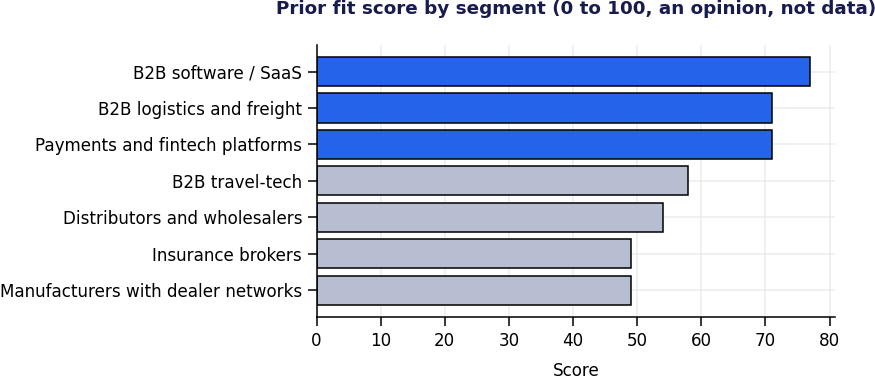

In [9]:
def fit_score(scores, weights):
    w = weights / weights.sum()
    return (scores[w.index].mul(w, axis=1).sum(axis=1) / 5 * 100).sort_values(ascending=False)

def weight_sensitivity(scores, weights, n=2000, concentration=20.0, seed=8402):
    rng = np.random.default_rng(seed)
    draws = rng.dirichlet((weights / weights.sum()).to_numpy() * concentration, size=n)
    s = scores[weights.index].to_numpy() @ draws.T
    ranks = np.argsort(np.argsort(-s, axis=0), axis=0) + 1
    return pd.DataFrame({"top1_share": (ranks == 1).mean(axis=1), "top3_share": (ranks <= 3).mean(axis=1),
                         "median_rank": np.median(ranks, axis=1)}, index=scores.index)

rank, sens = fit_score(SCORES, WEIGHTS), weight_sensitivity(SCORES, WEIGHTS)
ranking = pd.concat([rank.rename("fit score (0-100)"), sens], axis=1).sort_values("fit score (0-100)", ascending=False)
ranking.index = [SEGMENTS[i] for i in ranking.index]
display(SCORES.rename(index=SEGMENTS)); display(ranking.round(2))

r = ranking["fit score (0-100)"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(r.index, r.values, color=[BLUE if i >= len(r) - 3 else GREY for i in range(len(r))])
ax.set_title("Prior fit score by segment (0 to 100, an opinion, not data)"); ax.set_xlabel("Score")
save("07_prior_ranking")

**Reading this.** B2B software, B2B logistics and payments platforms rank above the rest, and the top three hold when the weights are shaken. That matches the deck's own sequence (software first, payments and others after) and the one segment with a real customer (logistics). Two cautions: the gaps are modest, and **software scores low on ability to pay** because many Kenyan SaaS firms are small. Whether enough clear the 1,000-account and $12,000 gates is the key unknown to test first.

## 8. How fast can we learn? Why win rates will not settle it by 31 January
Even if one segment truly converts at 30% and another at 15%, a handful of closed deals often shows the wrong winner. So the first 70 days must run on **leading indicators**: the share of prospects that agree to a scoping call, speed through stages, and recorded reasons for "no".

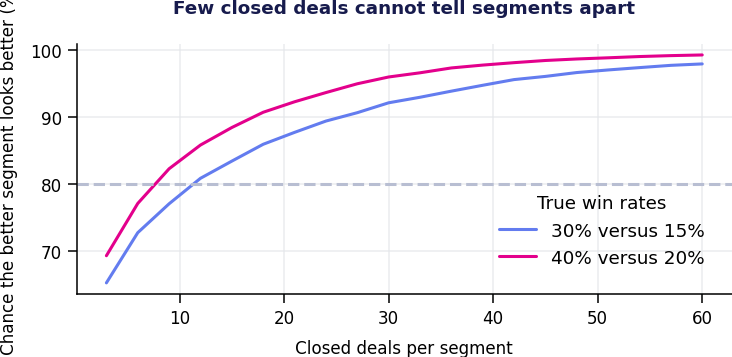

About 12 closed deals per segment are needed to be 80% sure when the true rates are 30% and 15%.


In [10]:
def separation(p_high, p_low, n_each, trials=4000, seed=7):
    rng = np.random.default_rng(seed)
    a, b = rng.binomial(n_each, p_high, trials), rng.binomial(n_each, p_low, trials)
    return float(((a > b).sum() + 0.5 * (a == b).sum()) / trials)

ns = list(range(3, 61, 3))
fig, ax = plt.subplots(figsize=(7, 3.6))
for ph, pl_ in [(0.30, 0.15), (0.40, 0.20)]:
    ax.plot(ns, [separation(ph, pl_, n) * 100 for n in ns], lw=2, label=f"{ph:.0%} versus {pl_:.0%}")
ax.axhline(80, color=GREY, ls="--"); ax.set_xlabel("Closed deals per segment"); ax.set_ylabel("Chance the better segment looks better (%)")
ax.set_title("Few closed deals cannot tell segments apart"); ax.legend(frameon=False, title="True win rates", loc="lower right")
save("08_learning_speed")
n80 = next(n for n in range(3, 200) if separation(0.30, 0.15, n) >= 0.8)
print(f"About {n80} closed deals per segment are needed to be 80% sure when the true rates are 30% and 15%.")

## 9. Key numbers and recommendations

In [11]:
pess, bs, opt = res["Pessimistic"], res["Base"], res["Optimistic"]
top3 = [SEGMENTS[i] for i in rank.index[:3]]
print(f"Days left: {days}. Contracts needed: {A['target']}. Assumed split: {dict(zip(A['stages'], counts))}")
print(f"Chance of 5+ contracts: pessimistic {pess['p']:.0%}, base {bs['p']:.0%}, optimistic {opt['p']:.0%}")
print("Top three prior segments:", top3)
print("Top-3 membership under weight shaking:", {SEGMENTS[i]: f"{sens.loc[i, 'top3_share']:.0%}" for i in rank.index[:4]})
print(f"Closed deals per segment to separate a 30% from a 15% segment with 80% confidence: {n80}")
print(f"Platform-fee value of five contracts at the gate size: USD {five_at_gate:,} a year")

Days left: 70. Contracts needed: 5. Assumed split: {'Identified': 55, 'Contacted': 25, 'Scoping call': 12, 'Quote sent': 6, 'Negotiation': 2}
Chance of 5+ contracts: pessimistic 7%, base 66%, optimistic 99%
Top three prior segments: ['B2B software / SaaS', 'B2B logistics and freight', 'Payments and fintech platforms']
Top-3 membership under weight shaking: {'B2B software / SaaS': '100%', 'B2B logistics and freight': '100%', 'Payments and fintech platforms': '100%', 'B2B travel-tech': '0%'}
Closed deals per segment to separate a 30% from a 15% segment with 80% confidence: 12
Platform-fee value of five contracts at the gate size: USD 60,000 a year


**Working hypothesis (not a finding).** Test **B2B software, B2B logistics and payments platforms** first, in parallel, as a structured experiment rather than a bet. Keep **travel-tech** as product proof (Triply is a related party). Hold **distributors, manufacturers and insurance brokers** until the first reads arrive.

| # | Action | Why | Owner (proposed) | When |
|---|---|---|---|---|
| 1 | **Close the late-stage deals first**, before opening new conversations | Only late-stage deals can still sign inside the window | Darren, with Liza | Now to 31 Jan |
| 2 | **Test software, logistics and payments in parallel**, using named lists from public registers | Gives a reachable pool beyond the founder's network | Darren | Weeks 1 to 2 |
| 3 | **Hold the other segments** until the first results are in | Stops effort leaking into weak segments | Darren | Review day 30 and day 60 |

**What we need from Darren.** The real stage split of the 100 prospects, whether Kijani already counts as paid, whether the $12,000 minimum applies in Kenya, and his written ICP criteria. Replace the assumptions in section 2, re-run, and the numbers update.

## 10. The tracker app
The simple tracker app turns this analysis into something Darren can use every week. He logs prospects by code, the app checks the three gates, values each prospect at the new pricing, and shows the chance of five contracts by 31 January using the same simulation as section 6.

- **Live app link:** *paste the link here once deployed*
- **Sample data:** `data/sample_pipeline.csv` (written by section 4) is the file the app loads under "Load sample data".
- **Rule:** use prospect codes, never people's names.
- **Free hosting forgets saved data on restart.** Download the pipeline CSV after each session.

In [12]:
results = {
    "days": days, "target": A["target"], "counts": dict(zip(A["stages"], counts)),
    "scenarios": {k: {"p": v["p"], "mean": v["mean"], "p10": v["p10"], "p90": v["p90"]} for k, v in res.items()},
    "extra": {r["Scenario"]: {"quote": r["Extra prospects at Quote sent for 80% chance"], "scoping": r["Extra prospects at Scoping call for 80% chance"]} for r in tbl},
    "stress": stress.to_dict(orient="records"),
    "ranking": {k: {"score": float(v["fit score (0-100)"]), "top1": float(v["top1_share"]), "top3": float(v["top3_share"])} for k, v in ranking.iterrows()},
    "n80": n80, "five_at_gate": five_at_gate, "legacy_annual": legacy,
    "price_table": price_table[price_table["revenue per account (USD)"] == 1500].to_dict(orient="records"),
    "universe": {"raw_rows": len(raw), "clean_rows": len(df), "pass": n_pass, "tier_a": tier_a, "tier_b": tier_b, "median_value_pass": float(v.median())},
    "planted": {k: v for k, v in planted.items() if isinstance(v, int)}, "cleaning": clog,
}
(OUT / "results.json").write_text(json.dumps(results, indent=2, default=float))
for name, t in {"price_table": price_table, "feasibility": feas, "stress_tests": stress, "prior_ranking": ranking, "audit": audit_table}.items():
    t.to_csv(OUT / f"{name}.csv", index=False)
print("Saved results.json, tables and charts to", OUT)

Saved results.json, tables and charts to /home/claude/work/outputs
